In [4]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data

In [ ]:
data_path = "dataset"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path)

In [ ]:
n_rows, n_cols = x_train.shape
print(f"Number of training samples: {n_rows}")
print(f"Number of features: {n_cols}")

Number of training samples: 328135
Number of features: 321


In [56]:
features_in_range = []

for col in range(n_cols):
    unique_vals = np.unique(x_train[:, col])
    num_unique = len(unique_vals)
    if 2 <= num_unique < 5:
        features_in_range.append(col)
        
print(f"Total number of features with 2 <= unique values < 5: {len(features_in_range)}")

features_with_5_unique = []
features_with_9_10_unique = []

for col in range(n_cols):
    unique_vals = np.unique(x_train[:, col])
    num_unique = len(unique_vals)
    if num_unique == 5:
        features_with_5_unique.append(col)
    if num_unique == 9 or num_unique == 10:
        features_with_9_10_unique.append(col)

print(f"Number of features with exactly 5 unique values: {len(features_with_5_unique)}")
print(f"Number of features with exactly 9 or 10 unique values: {len(features_with_9_10_unique)}")


Total number of features with 2 <= unique values < 5: 73
Number of features with exactly 5 unique values: 75
Number of features with exactly 9 or 10 unique values: 19


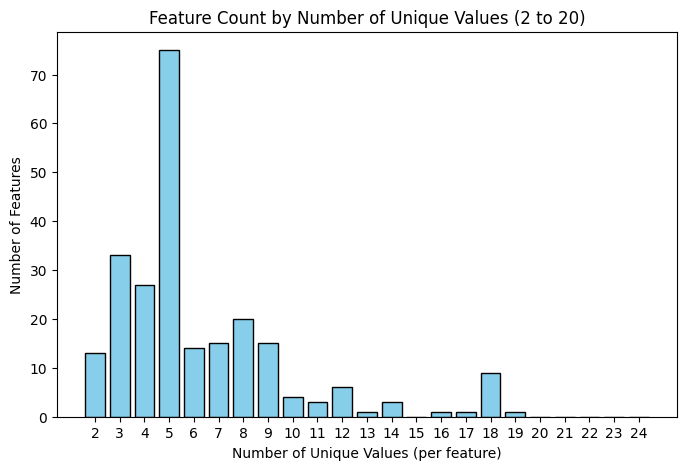

In [69]:
# Count number of features for each unique value count between 2 and 21
unique_value_counts = np.array([len(np.unique(x_train[:, col])) for col in range(n_cols)])
value_bins = np.arange(2, 25)
features_per_unique_count = [(unique_value_counts == v).sum() for v in value_bins]

plt.figure(figsize=(8, 5))
plt.bar(value_bins, features_per_unique_count, color="skyblue", edgecolor="black")
plt.xlabel("Number of Unique Values (per feature)")
plt.ylabel("Number of Features")
plt.title("Feature Count by Number of Unique Values (2 to 20)")
plt.xticks(value_bins)
plt.show()

In [58]:
categorical_features = []
ordinal_features = []
numerical_features = []

for col in range(n_cols):
    unique_vals = np.unique(x_train[:, col])
    num_unique = len(unique_vals)
    if 2 <= num_unique <= 9 and num_unique != 5:
        categorical_features.append(col)
    elif num_unique == 5:
        ordinal_features.append(col)
    else:
        numerical_features.append(col)

print(f"Number of categorical features (unique values 2-9 except 5): {len(categorical_features)}")
print(f"Number of ordinal features (unique values = 5): {len(ordinal_features)}")
print(f"Number of numerical features (all others): {len(numerical_features)}")


Number of categorical features (unique values 2-9 except 5): 137
Number of ordinal features (unique values = 5): 75
Number of numerical features (all others): 109


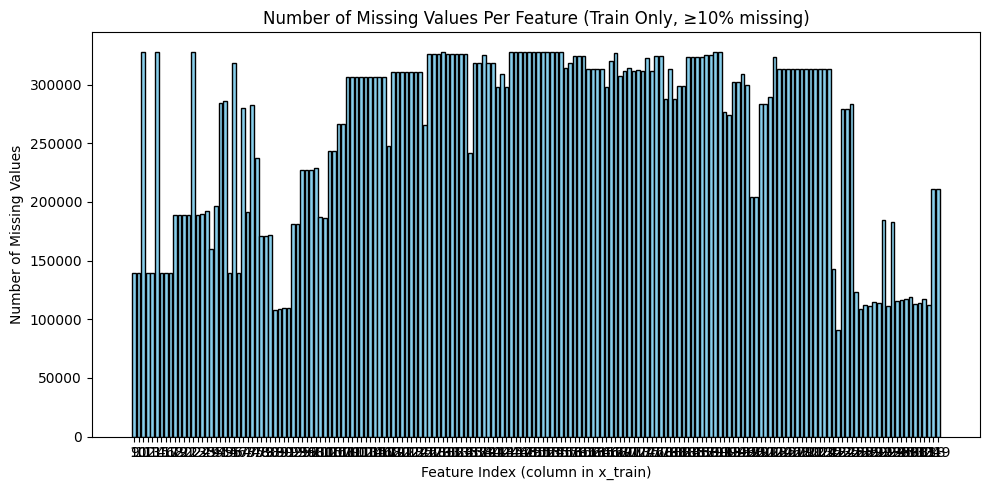

In [70]:
# For all features, plot the number of missing values (training set only)
# Only show features where at least 10% of the rows are missing

n_rows = x_train.shape[0]
missing_per_feature = np.sum(np.isnan(x_train), axis=0)  # shape (n_cols,)
percent_missing = missing_per_feature / n_rows

# Filter: only keep features with at least 10% missing values
threshold = 0.20
filtered_indices = np.where(percent_missing >= threshold)[0]
filtered_missing_counts = missing_per_feature[filtered_indices]
filtered_percent_missing = percent_missing[filtered_indices]

plt.figure(figsize=(10, 5))
x = np.arange(len(filtered_indices))

plt.bar(x, filtered_missing_counts, color='skyblue', edgecolor="black")

plt.xlabel("Feature Index (column in x_train)")
plt.ylabel("Number of Missing Values")
plt.title("Number of Missing Values Per Feature (Train Only, ≥10% missing)")
plt.xticks(x, filtered_indices)
plt.tight_layout()
plt.show()


In [ ]:
n_missing_train = np.sum(np.isnan(x_train))

print(f"Number of missing values in x_train: {n_missing_train}")

# Optionally, show which columns have missing values and how many per column
missing_per_col_train = np.sum(np.isnan(x_train), axis=0)
print("\nMissing values per column in x_train:")
for col_idx, miss_count in enumerate(missing_per_col_train):
    if miss_count > 0:
        print(f"  Column {col_idx}: {miss_count} missing")

missing_per_col_test = np.sum(np.isnan(x_test), axis=0)
print("\nMissing values per column in x_test:")
for col_idx, miss_count in enumerate(missing_per_col_test):
    if miss_count > 0:
        print(f"  Column {col_idx}: {miss_count} missing")


Number of missing values in x_train: 47175779

Missing values per column in x_train:
  Column 9: 139415 missing
  Column 10: 139415 missing
  Column 11: 328103 missing
  Column 12: 139416 missing
  Column 13: 139415 missing
  Column 14: 328103 missing
  Column 15: 139433 missing
  Column 16: 139524 missing
  Column 17: 139525 missing
  Column 18: 188720 missing
  Column 19: 188720 missing
  Column 20: 188721 missing
  Column 21: 188720 missing
  Column 22: 327334 missing
  Column 23: 188719 missing
  Column 24: 189287 missing
  Column 25: 192544 missing
  Column 26: 2 missing
  Column 27: 1 missing
  Column 29: 159860 missing
  Column 32: 1 missing
  Column 33: 1 missing
  Column 34: 1 missing
  Column 35: 196334 missing
  Column 37: 43801 missing
  Column 38: 43801 missing
  Column 41: 284153 missing
  Column 42: 1 missing
  Column 45: 1 missing
  Column 48: 5 missing
  Column 49: 285915 missing
  Column 54: 139415 missing
  Column 55: 318245 missing
  Column 56: 139415 missing
  Colu